# Statystyki konkretnego treningu

In [1]:
import sys
from pathlib import Path
PROJECT_ROOT = Path.cwd().parent
sys.path.insert(0, str(PROJECT_ROOT))
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from model.training_orchiestration import ModelRun


MODEL_CATALOG = PROJECT_ROOT / "model" / "model_catalog"
DATA_PATH = PROJECT_ROOT / "data"

RUN_NAME = "20261121_231847_TrainingMode.FULL_9daa12" #do wpisania nazwa katalogu gdzie jest model


RUN_DIR = MODEL_CATALOG / RUN_NAME
run = ModelRun(RUN_DIR)

print("Selected run:", RUN_DIR)
print("Config:", run.config.to_dict())

Selected run: c:\Users\Bcom_\Documents\Projekty\SpeakerAnimator\SpeakerAnimatorPython\model\model_catalog\20261121_231847_TrainingMode.FULL_9daa12
Config: {'data_path': '../data', 'train_split_name': 'train_clean_100', 'test_split_name': 'test_clean', 'debug_size': 200, 'seed': 0, 'val_ratio': 0.1, 'model_arch': 'tds', 'tds_blocks': 4, 'tds_kernel_size': 17, 'tds_expansion': 2, 'norm_type': 'batch', 'norm_groups': 8, 'lstm_layers': 2, 'sample_rate': 16000, 'n_fft': 400, 'hop_length': 160, 'n_mels': 80, 'ignore_index': -100, 'min_silence_duration': 0.1, 'gain_aug_db': 18.0, 'include_leading_silence': True, 'include_trailing_silence': True, 'hidden_dim': 256, 'dropout': 0.2, 'use_flatness': True, 'flatness_eps': 1e-08, 'num_epochs': 15, 'batch_size': 8, 'lr': 0.0003, 'num_workers': 4, 'prefetch_factor': 2, 'use_amp': True, 'mode': 'full', 'model_catalog_dir': './model_catalog'}


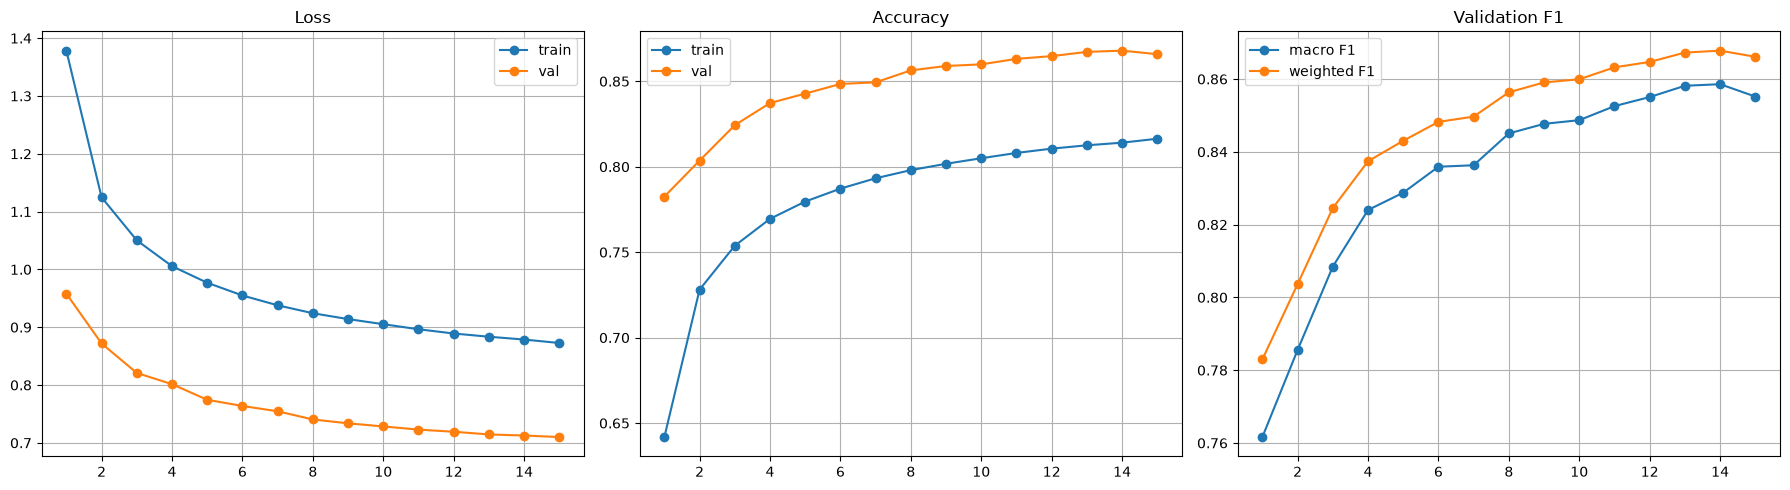

In [2]:
history_path = RUN_DIR / "training_history.json"

with open(history_path, "r", encoding="utf-8") as f:
    history = json.load(f)

df = pd.DataFrame(history)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

axes[0].plot(df["epoch"], df["train_loss"], marker="o", label="train")
axes[0].plot(df["epoch"], df["val_loss"], marker="o", label="val")
axes[0].set_title("Loss")
axes[0].legend()
axes[0].grid(True)

axes[1].plot(df["epoch"], df["train_acc"], marker="o", label="train")
axes[1].plot(df["epoch"], df["val_acc"], marker="o", label="val")
axes[1].set_title("Accuracy")
axes[1].legend()
axes[1].grid(True)

if "val_f1_macro" in df.columns:
    axes[2].plot(df["epoch"], df["val_f1_macro"], marker="o", label="macro F1")
    axes[2].plot(df["epoch"], df["val_f1_weighted"], marker="o", label="weighted F1")
    axes[2].set_title("Validation F1")
    axes[2].legend()
    axes[2].grid(True)

plt.tight_layout()
plt.show()

In [3]:
from datasets import load_from_disk

dataset = load_from_disk(DATA_PATH)
test_split = dataset["test_clean"]

test_results = run.test(test_split, batch_size=4, num_workers=0)

c:\Users\Bcom_\Documents\Projekty\SpeakerAnimator\SpeakerAnimatorPython\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Testing using device: cuda


Precomputing test features: 100%|██████████| 2620/2620 [00:32<00:00, 80.72it/s] 


Precomputing test features: mel -23.88±17.40 | flat -21.16±9.74


Test loss: 0.4920
Test accuracy: 0.8556
Silence evaluated: True
              precision    recall  f1-score   support

          CH       0.75      0.97      0.85     41551
          DD       0.87      0.78      0.82    157366
           E       0.81      0.87      0.84    139862
          FF       0.78      0.92      0.85     64359
           I       0.83      0.81      0.82    165121
           O       0.75      0.87      0.80     65995
          PP       0.84      0.89      0.87    100925
          RR       0.85      0.89      0.87    118041
          SS       0.91      0.93      0.92    155571
          TH       0.73      0.88      0.80     45343
           U       0.78      0.87      0.83     62985
          aa       0.86      0.74      0.79    221189
          kk       0.83      0.89      0.86     96019
          nn       0.86      0.82      0.84    179086
         sil       0.98      0.90      0.94    318343

    accuracy                           0.86   1931756
   macro avg    

In [4]:
report = test_results["report_dict"]

non_class_keys = {
    "accuracy",
    "macro avg",
    "weighted avg",
    "micro avg",
    "samples",
}

rows = []

for key, value in report.items():
    if key in non_class_keys:
        continue

    if isinstance(value, dict):
        rows.append(
            {
                "class": key,
                "precision": value.get("precision"),
                "recall": value.get("recall"),
                "f1-score": value.get("f1-score"),
                "support": value.get("support"),
            }
        )

per_class = pd.DataFrame(rows)
per_class = per_class.sort_values("support", ascending=False)

per_class

,class,precision,recall,f1-score,support
14,sil,0.976819,0.903152,0.938542,318343.0
11,aa,0.856189,0.739657,0.793668,221189.0
13,nn,0.864717,0.819629,0.841569,179086.0
4,I,0.828026,0.807947,0.817863,165121.0
1,DD,0.867838,0.781179,0.822231,157366.0
8,SS,0.907766,0.933201,0.920308,155571.0
2,E,0.811685,0.869772,0.839725,139862.0
7,RR,0.848159,0.892664,0.869843,118041.0
6,PP,0.842802,0.889165,0.865363,100925.0
12,kk,0.831981,0.885200,0.857766,96019.0


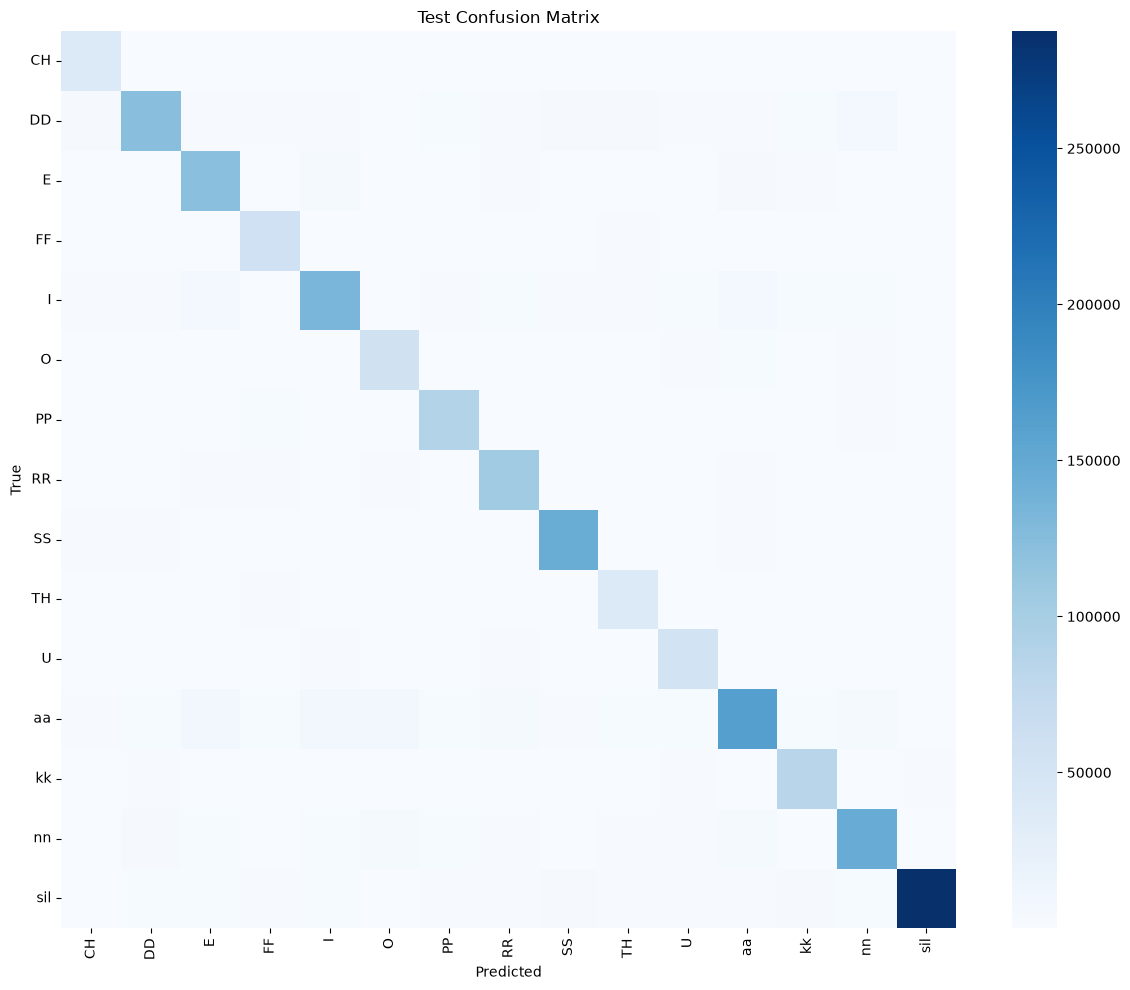

In [5]:
cm = np.array(test_results["confusion_matrix"])
labels = test_results["labels"]

plt.figure(figsize=(12, 10))

sns.heatmap(
    cm,
    annot=False,
    fmt="d",
    cmap="Blues",
    xticklabels=labels,
    yticklabels=labels,
)

plt.title("Test Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("True")
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

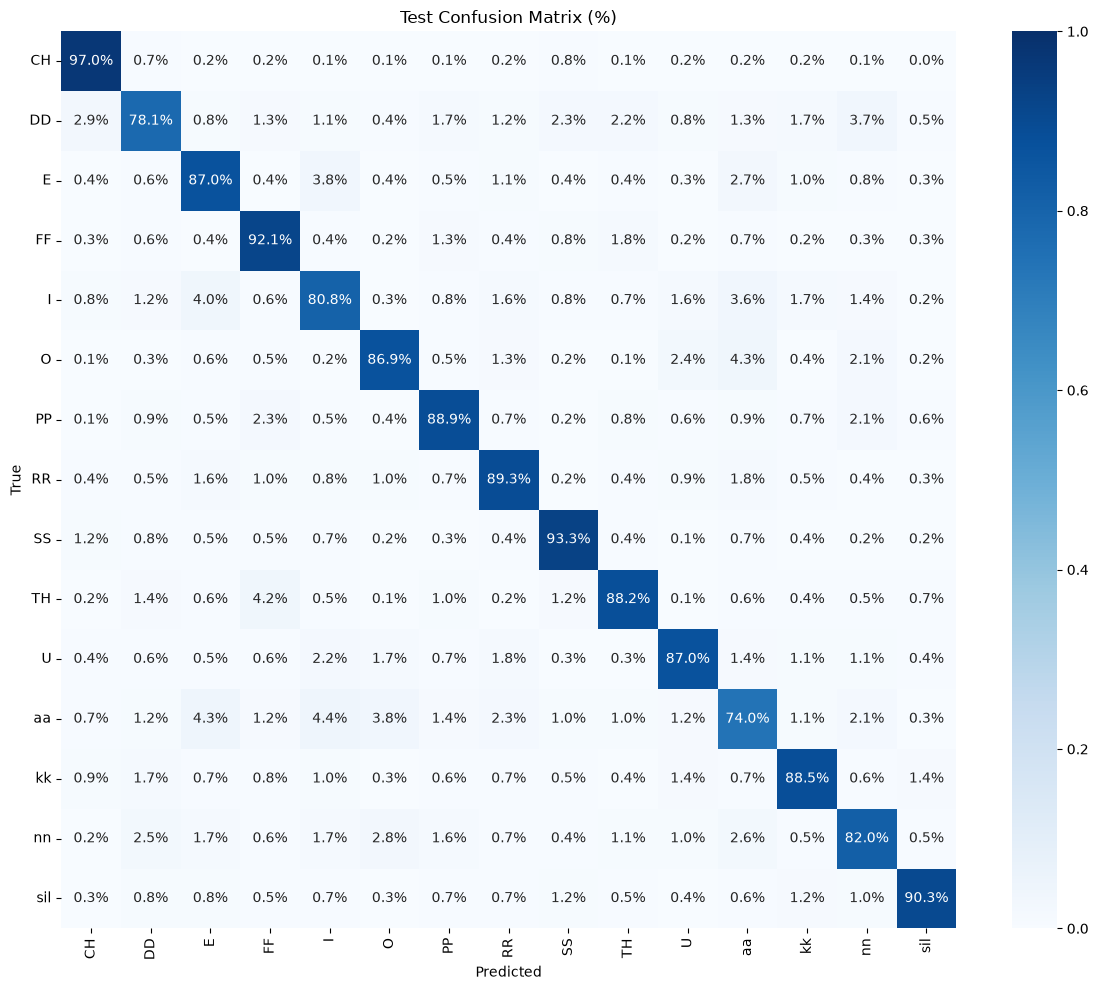

In [6]:
cm = np.array(test_results["confusion_matrix"], dtype=np.float64)
labels = test_results["labels"]

row_sums = cm.sum(axis=1, keepdims=True)

cm_norm = np.divide(
    cm,
    row_sums,
    out=np.zeros_like(cm),
    where=row_sums != 0,
)

plt.figure(figsize=(12, 10))

sns.heatmap(
    cm_norm,
    annot=True,
    fmt=".1%",
    cmap="Blues",
    xticklabels=labels,
    yticklabels=labels,
    vmin=0,
    vmax=1,
)

plt.title("Test Confusion Matrix (%)")
plt.xlabel("Predicted")
plt.ylabel("True")
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

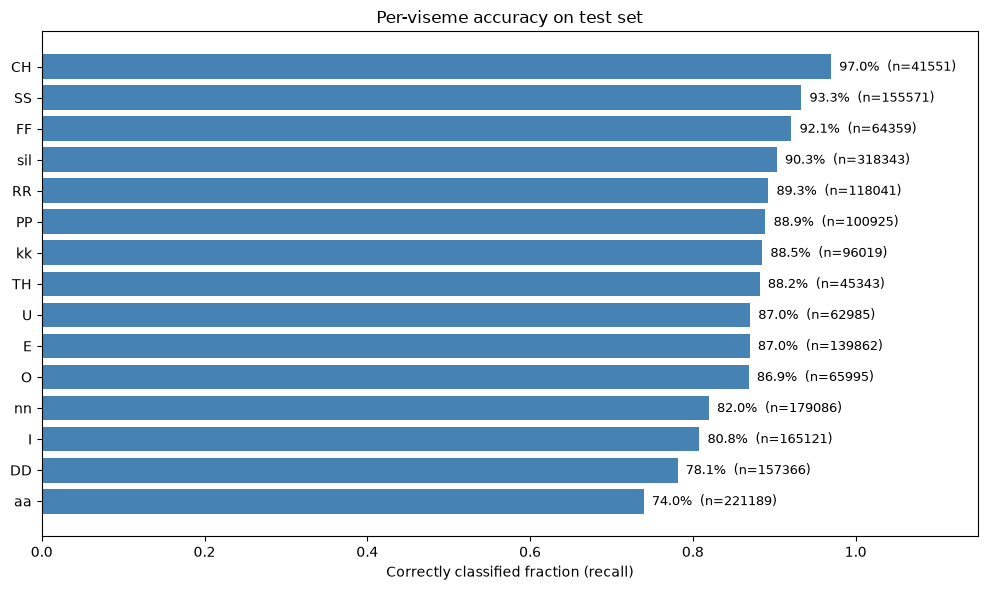

In [7]:
cm_counts = np.array(test_results["confusion_matrix"], dtype=np.int64)
recall_per_class = np.diag(cm_norm)
support = cm_counts.sum(axis=1)

order = np.argsort(recall_per_class)

plt.figure(figsize=(10, 6))
plt.barh(
    [labels[i] for i in order],
    recall_per_class[order],
    color="steelblue",
)

for idx, i in enumerate(order):
    plt.text(
        recall_per_class[i] + 0.01,
        idx,
        f"{recall_per_class[i]:.1%}  (n={support[i]})",
        va="center",
        fontsize=9,
    )

plt.xlim(0, 1.15)
plt.xlabel("Correctly classified fraction (recall)")
plt.title("Per-viseme accuracy on test set")
plt.tight_layout()
plt.show()

In [8]:
import IPython.display as ipd

sample_idx = 0
sample = test_split[sample_idx]

audio_array = sample["audio"]["array"]
sample_rate = sample["audio"]["sampling_rate"]

probs, labels = run.predict_audio(
    audio_array,
    sample_rate=sample_rate,
)

print("Probability shape:", probs.shape)
print("Labels:", labels)

print("Transcript:", sample.get("transcript"))

ipd.display(
    ipd.Audio(audio_array, rate=sample_rate)
)

Probability shape: (1056, 15)
Labels: ['CH', 'DD', 'E', 'FF', 'I', 'O', 'PP', 'RR', 'SS', 'TH', 'U', 'aa', 'kk', 'nn', 'sil']
Transcript: the dull light fell more faintly upon the page whereon another equation began to unfold itself slowly and to spread abroad its widening tail


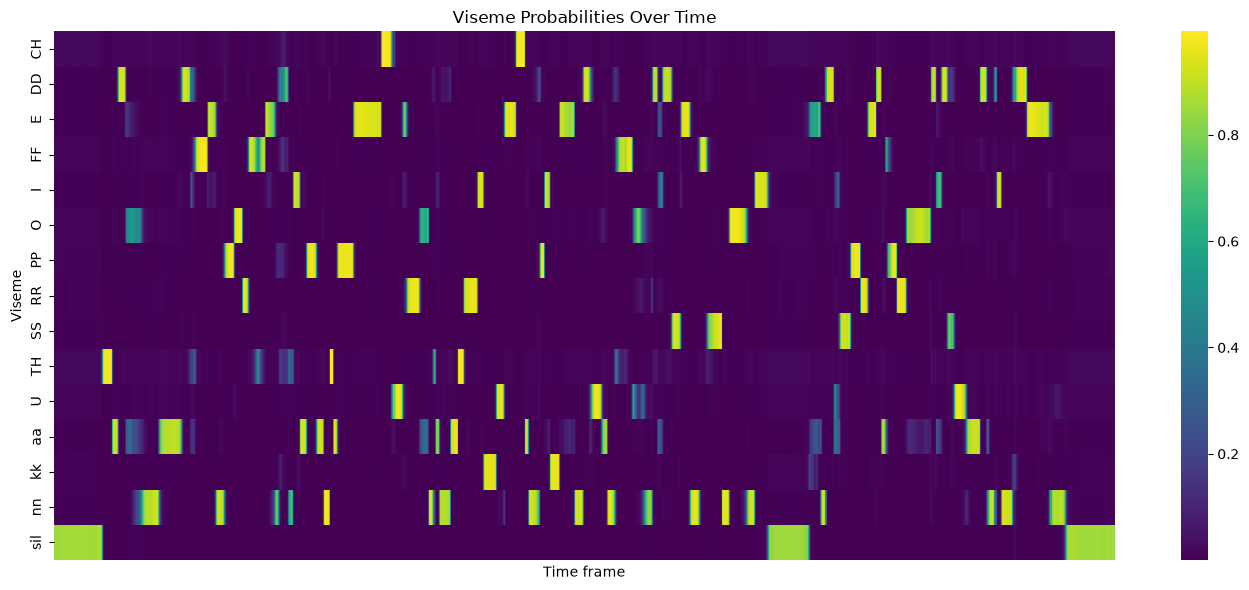

In [9]:
plt.figure(figsize=(14, 6))

sns.heatmap(
    probs.T,
    cmap="viridis",
    yticklabels=labels,
    xticklabels=False,
)

plt.title("Viseme Probabilities Over Time")
plt.xlabel("Time frame")
plt.ylabel("Viseme")
plt.tight_layout()
plt.show()

In [10]:
pred_ids = probs.argmax(axis=1)
pred_labels = [labels[i] for i in pred_ids]

def collapse_repeated(sequence):
    collapsed = []

    for item in sequence:
        if len(collapsed) == 0 or collapsed[-1] != item:
            collapsed.append(item)

    return collapsed

collapsed_visemes = collapse_repeated(pred_labels)

print("Collapsed predicted visemes:")
print(" ".join(collapsed_visemes[:100]))

Collapsed predicted visemes:
sil TH aa DD O nn aa DD FF E nn PP O RR FF E nn DD nn I aa PP aa nn TH aa PP E CH U E RR O nn TH aa nn aa TH RR I kk U E CH aa nn PP I kk E nn DD U aa nn FF U O U nn DD aa I DD SS E nn FF SS nn O nn I sil E nn DD U aa I aa SS PP RR E DD aa FF PP RR O DD I DD SS U aa DD nn
